In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import nltk

In [4]:
df = pd.read_csv("data/spam.csv", encoding="latin1")
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
4639,ham,Do you hide anythiing or keeping distance from me,NaN,NaN,NaN
2923,ham,Thts god's gift for birds as humans hav some n...,NaN,NaN,NaN
1075,ham,Oi. Ami parchi na re. Kicchu kaaj korte iccha ...,NaN,NaN,NaN
4333,ham,Boo what time u get out? U were supposed to ta...,NaN,NaN,NaN
4395,ham,Dear :-/ why you mood off. I cant drive so i b...,NaN,NaN,NaN


In [5]:
df.drop(columns = ["Unnamed: 2","Unnamed: 3","Unnamed: 4"],inplace = True)
df.rename(columns = {"v1":"target","v2":"text"},inplace = True)

In [6]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [7]:
df["target"]  = encoder.fit_transform(df["target"])

In [8]:
df = df.drop_duplicates(keep = "first")

In [9]:
nltk.download("punkt")

[nltk_data] Downloading package punkt to C:\Users\ANGEL
[nltk_data]     COMPUTERS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [10]:
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt_tab to C:\Users\ANGEL
[nltk_data]     COMPUTERS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [11]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to C:\Users\ANGEL
[nltk_data]     COMPUTERS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [14]:
df["num_char"] = df["text"].apply(len)
df["num_word"] = df["text"].apply(lambda x:len(nltk.word_tokenize(x)))
df["num_sent"] = df["text"].apply(lambda x:len(nltk.sent_tokenize(x)))

In [15]:
df.describe()

,target,num_char,num_word,num_sent
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,0.126330,78.977945,18.460437,1.965564
std,0.332253,58.236293,13.334441,1.448541
min,0.000000,2.000000,1.000000,1.000000
25%,0.000000,36.000000,9.000000,1.000000
50%,0.000000,60.000000,15.000000,1.000000
75%,0.000000,117.000000,26.000000,2.000000
max,1.000000,910.000000,220.000000,38.000000


In [16]:
df[df["target"] == 0][["num_char","num_word","num_sent"]].describe()

,num_char,num_word,num_sent
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [17]:
df[df["target"] == 1][["num_char","num_word","num_sent"]].describe()

,num_char,num_word,num_sent
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


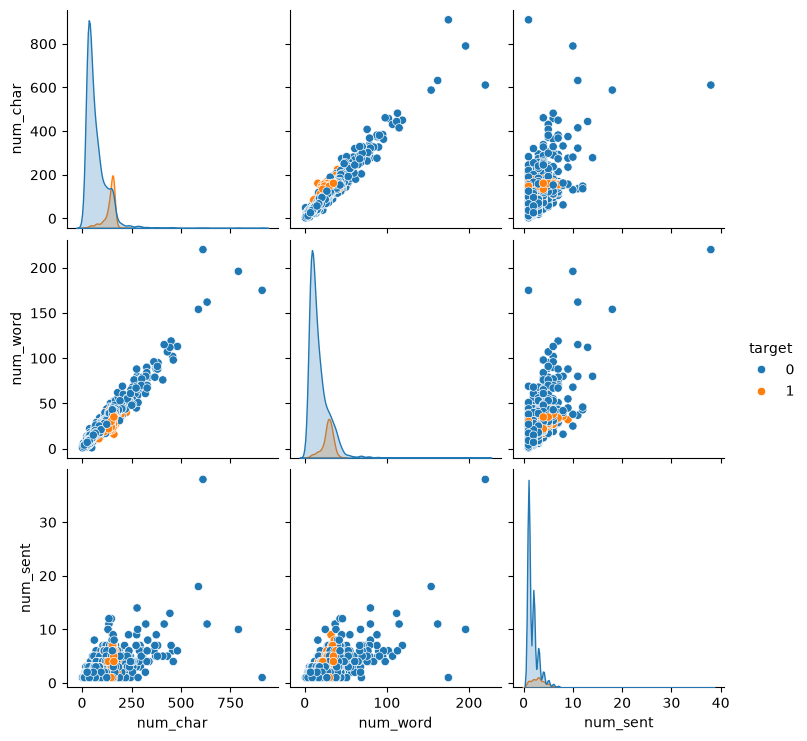

In [18]:
sns.pairplot(df,hue ="target")

<Axes: >

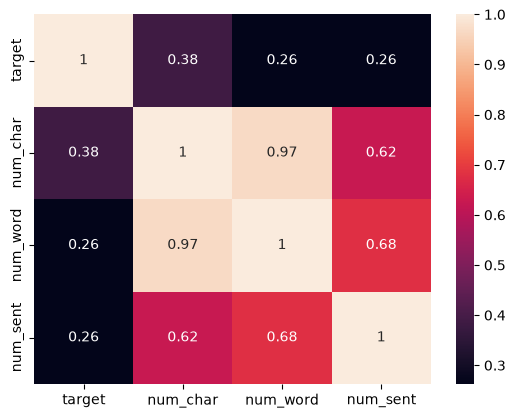

In [19]:
sns.heatmap(df[["target","num_char","num_word","num_sent"]].corr(),annot = True)

In [20]:
from nltk.corpus import stopwords
import string
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

In [21]:
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    text = y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words("english") and i not in string.punctuation:
            y.append(i)
        
    text = y[:]
    y.clear()

    for i in text:
      y.append(ps.stem(i))
           
    return " ".join(y)

In [22]:
df["transformed_text"] = df["text"].apply(transform_text)

In [23]:
from wordcloud import WordCloud
wc = WordCloud(width = 500,height = 500,min_font_size = 10,background_color = "black")

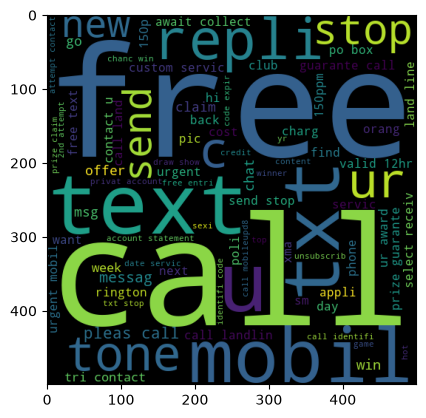

In [24]:
wc = wc.generate(df[df["target"] == 1]["transformed_text"].str.cat(sep = " "))
plt.imshow(wc)

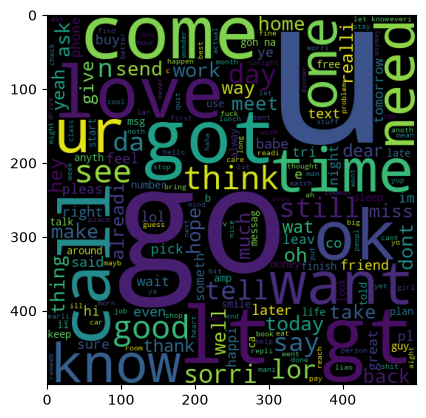

In [25]:
wc = wc.generate(df[df["target"] == 0]["transformed_text"].str.cat(sep = " "))
plt.imshow(wc)

In [26]:
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features = 3000)

In [27]:
x = tfidf.fit_transform(df["transformed_text"]).toarray()
y = df["target"]

In [28]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,
                                                 y,
                                                 test_size = 0.3,
                                                 random_state = 42
                                                )

In [29]:
from imblearn.over_sampling  import SMOTE
smo = SMOTE()
x_resample,y_resample = smo.fit_resample(x_train,y_train)

In [30]:
from sklearn.naive_bayes import GaussianNB,BernoulliNB,MultinomialNB

gnb = GaussianNB()
bnb = BernoulliNB()
mnb = MultinomialNB()

In [40]:
from sklearn.metrics import confusion_matrix,precision_score
bnb.fit(x_resample,y_resample)
bnb_pred = bnb.predict(x_test)
print(accuracy_score(y_test,bnb_pred))
print(confusion_matrix(y_test,bnb_pred))
print(precision_score(y_test,bnb_pred))

0.9838813668600903
[[1329    2]
 [  23  197]]
0.9899497487437185


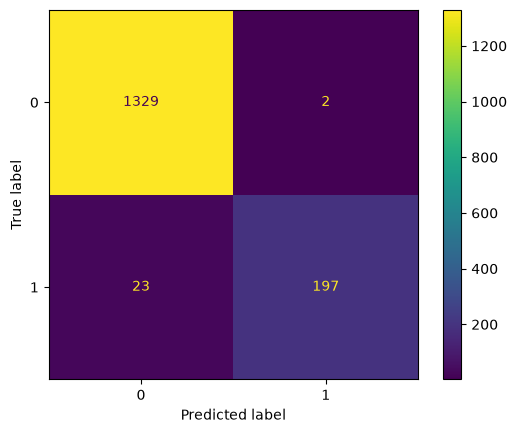

In [39]:
from sklearn.metrics  import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test,bnb_pred)

In [190]:
import pickle
pickle.dump(tfidf,open("vectorizer.pkl","wb"))
pickle.dump(bnb,open("model.pkl","wb"))